# Zeeman effect 
### (Cornelius Gahl, 10/2024) 

In [1]:
import sys
import os
import glob
import time

import math
import numpy as np
import scipy as sp
import matplotlib.pyplot as mpl

from lmfit import Minimizer, Parameters, report_fit
import asteval
import uncertainties


In [5]:
# *** Define constants ***
mubohr= 9.2740e-24       # Bohr magneton
hbar= 1.05457e-34      
ee=   1.60218e-19        # elementary charge
cc= 299792458            # speed of light

lambda0=546.0735e-9           # wavelength of the green Hg emission line

lambda2eV= cc*hbar/ee*np.pi*2   #conversion between wavelength (in meter) and energy (in eV):  Energy= lambda2eV / lambda

# Experimental parameters:
dd=2.442e-3             # Fabri-Perot: plate distance  
pixelsize=3.75e-6       # distance between camera pixels

centerpixel=  122.7     # Replace by the Center pixel of interference rings!!!!!

# Calibration of the electromagnet
I_solenoid = [ 0, 6, 8, 10, 12, 14, 16, 18, 20]
Bfield = [ 0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]    # Put in here more precise field values!!!!!

# Define the path to your data
path_data="C:/Users/cgahl/Documents/FU/Lehre/BFP/Experimente/Ba09_Zeeman-Effekt/B09_Daten_Dokumentation/Zeeman_cg241004/2024-10-04/"
path_data2="C:/Users/cgahl/Documents/FU/Lehre/BFP/Experimente/Ba09_Zeeman-Effekt/B09_Daten_Dokumentation/Zeeman_cg241004/"


### Load data

In [6]:
#  *** LOAD image DATA ***
#  ***********************
data_darkimage = np.loadtxt(path_data + "13Uhr34_image.dat", unpack=False)
data_image1    = np.loadtxt(path_data + "20Uhr01_image.dat", unpack=False)

pixel = np.arange(0,1280,1)
print(pixel)

[   0    1    2 ... 1277 1278 1279]


In [7]:
#  *** LOAD image DATA ***
data_d1=np.loadtxt("C:/Users/cgahl/Documents/FU/Lehre/BFP/Experimente/Ba09_Zeeman-Effekt/B09_Daten_Dokumentation/Zeeman_cg241004/2024-10-07/16Uhr08_image.dat", unpack=False)


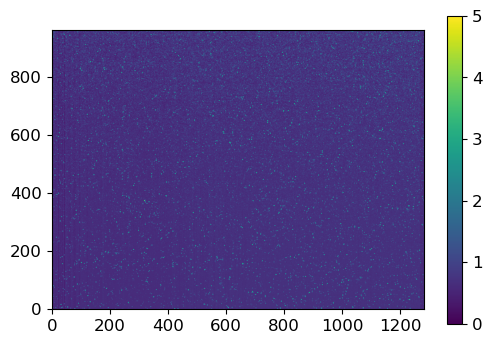

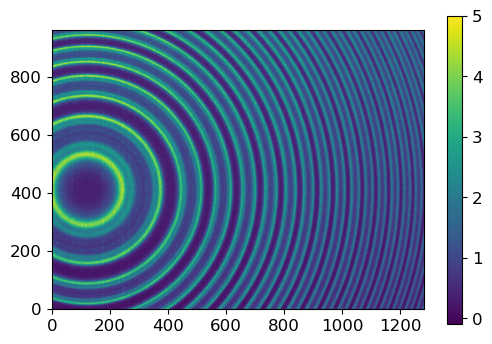

In [45]:
# *** Plotting images ***
# ***********************

mpl.figure(figsize=(6,4))          # defines plot size
mpl.rc('xtick', labelsize=12)   
mpl.rc('ytick', labelsize=12)   

mpl.imshow(data_d1.T/5000, cmap='viridis',origin='lower', aspect=1, vmax = 5)  
# .T transposes the 2D matrix, origin defines where the (0,0) pixel is on the graph
# aspect defines the ratio between x- and y-ticks

mpl.colorbar()                     # adds color bar

#mpl.xlim(0,250)
#mpl.ylim(280,530)



# *** another figure with background subtracted ***
mpl.figure(figsize=(6,4))

mpl.imshow(data_image1.T/600 - data_d1.T/5000  , cmap='viridis',origin='lower', aspect=1, vmax = 5) 
# vmax defines the max value of the color scale. Accordingly, vmin would set the min.

mpl.colorbar()
#mpl.xlim(0,300)
#mpl.ylim(230,580)

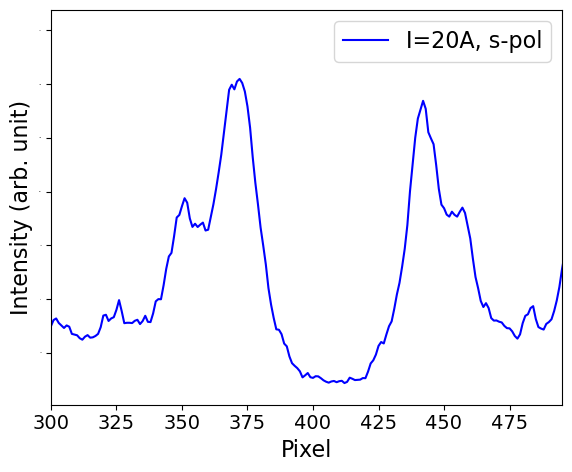

In [46]:
# *** Take line-outs from images vs pixel ***
# *******************************************
mpl.rcParams.update({'font.size': 16})              # changes font size for plots
mpl.figure(figsize=(6,5))
mpl.rc('xtick', labelsize=14)   
mpl.rc('ytick', labelsize=0)   
mpl.xlabel('Pixel')
mpl.ylabel('Intensity (arb. unit)')

mpl.plot(pixel,(data_image1[:, 380:420]/600-data_d1[:,380:420]/5000).sum(axis=1),'b', markersize=3,label='I=20A, s-pol') 
# [:, 380:420] takes all point in x-direction and only 380--420 in y-direction
# ().sum(axis=1) sums up all data points along the specified axis 1, in this case from pixel 380 to 420
# 

mpl.xlim(300,495)
#mpl.ylim(-10000,200000)
mpl.legend()
mpl.tight_layout()



In [50]:
# ***  SAVE line-out DATA ***
# ***************************

# take a line-out
spectrum = (data_image1[:, 380:420]/600-data_d1[:,380:420]/5000).sum(axis=1)


# write to file
filename="FabryPerotspectrum.dat"               # specify here the name of the output file
with open(filename, "w") as outfile:     # file stays open for the indented block of code
    for i in range(0,1280):
            #print(str(pixel[i]),"\t",str(spectrum[i]), file=outfile)   simple, but bad solution...
            #print("{0:.4f}\t{1:1.6e}".format(pixel[i], spectrum[i]), file=outfile)
            #print("{0:4d}\t{1:10.2f}".format(pixel[i], spectrum[i]), file=outfile)
            print(f'{pixel[i]:.0f}\t{spectrum[i]:10.2f}', file=outfile)

            
print("data written to file: ", filename)


data written to file:  FabryPerotspectrum.dat


In [51]:
#  *** LOAD line-out DATA ***
#  **************************
data_20A_s=np.loadtxt(path_data2+"FabryPerotspectrum.dat", unpack=False)
#data_0A_lin=np.loadtxt(path_data+"20Uhr01_intensity.dat", unpack=False)
pixel_0, intens_0 =np.hsplit(data_20A_s,2)

pixel= pixel_0[:,0]                          # reducing 2D array to 1D array
int_20A_s=intens_0 [:,0]=intens_0 [:,0]

radius= (centerpixel-pixel)*pixelsize        # axis for intensity as function of distance to ring center

In [52]:
# *** LOAD peak positions evaluated by reading position of peak maxima ***
# ************************************************************************
data_max_0A_lin=np.loadtxt("C:/Users/cgahl/Documents/FU/Lehre/BFP/Experimente/Ba09_Zeeman-Effekt/B09_Daten_Dokumentation/Zeeman_cg241004/20Uhr12_peaks.txt", unpack=False)
order_0, peakpos_0 =np.hsplit(data_max_0A_lin,2)
order_0A_lin= order_0[:,0]
peakpos_0A_lin= peakpos_0[:,0]

radius_0A_lin= -(centerpixel - peakpos_0A_lin) * pixelsize            # convert pixel to radius


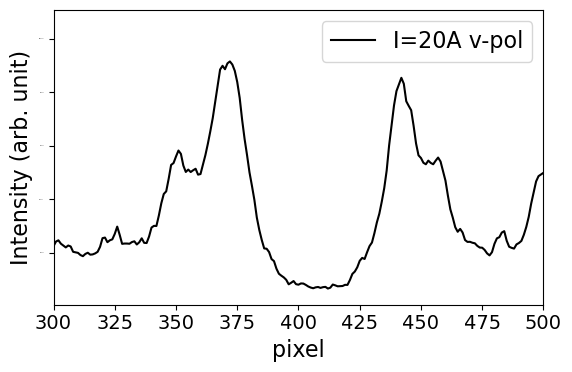

In [53]:
# *** PLOT data line-out ***
# **************************

mpl.rcParams.update({'font.size': 16})                        # changes general font size for plots
mpl.figure(figsize=(6,4))
mpl.rc('xtick', labelsize=14)                                 # define font size for labels
mpl.rc('ytick', labelsize=0)   

mpl.plot(pixel,int_20A_s,'k', markersize=3,label='I=20A v-pol')     # plotting command:   .plot(x-data, y-data, color, ...)

mpl.xlabel('pixel')
mpl.ylabel('Intensity (arb. unit)')
mpl.legend()

mpl.xlim(300,500)                                             # defines limits of x axis
#mpl.ylim(15000,62000)

mpl.tight_layout()                                            # makes sure that all labels are within plotting range

#mpl.savefig("Zeeman_splitting_pixel.png")        # The ending .png determines the file format. You can also save as ".pdf"

### Determination of focal length

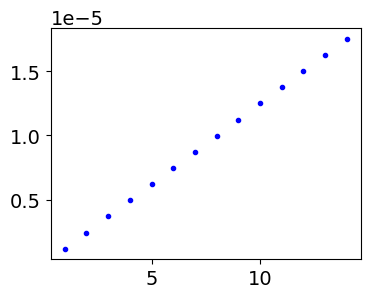

In [18]:
# *** Plot radius^2 of peak maxima as a function of (relative) interference order ***
# ***********************************************************************************
mpl.figure(figsize=(4,3))
mpl.rc('ytick', labelsize=14) 
mpl.plot(order_0A_lin,(-(centerpixel-peakpos_0A_lin)*pixelsize)**2,'b.', linewidth=2,zorder=10)   

In [19]:
# *** Fit squared ring radii to extract the focal length of the objective lens ***
# ********************************************************************************

centerpixel= 122.7       # *** value optimized to 0.1 for minimum Delta_f and statistical residuals ***
radius_0A_lin= -(centerpixel - peakpos_0A_lin) * pixelsize


pars, cov = np.polyfit(x=order_0A_lin, y=radius_0A_lin**2, deg=1, w=None, cov=True)
focus= np.sqrt(pars[0]*dd/lambda0)        # focal length is calculated from slope of fit (pars[0])

print(pars)
print(np.sqrt(np.diag(cov)))
print("f=",focus)
print("Delta_f=",focus*np.sqrt(np.diag(cov)[0])/pars[0]*0.5)   # uncertainty propagation from slope to focus

# Create fit wave with obtained parameters 
fit_x=np.linspace(start=0,stop=15,num=100)
fit_y=np.poly1d(pars)

[ 1.25990135e-06 -1.00376813e-07]
[2.47868587e-10 2.11052497e-09]
f= 0.07506120808294649
Delta_f= 7.383639821399046e-06


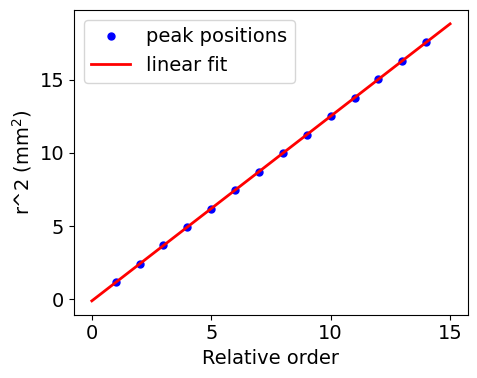

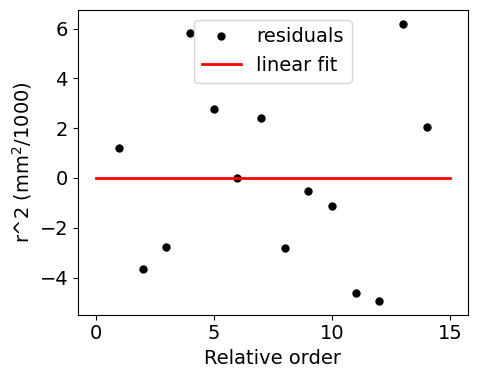

In [20]:
# *** Plot fit results ***
mpl.figure(figsize=(5,4))
mpl.rcParams.update({'font.size': 14})  
mpl.rc('ytick', labelsize=14) 

mpl.plot(order_0A_lin,radius_0A_lin**2 * 1e6,'b.',markersize=10, label='peak positions')  
mpl.plot(fit_x,fit_y(fit_x)* 1e6,'r-', linewidth=2,zorder=10, label='linear fit')  

mpl.xlabel('Relative order')
mpl.ylabel('r^2 (mm$^2$)')
mpl.legend()
mpl.tight_layout()

# *** Plot residuals ***
mpl.figure(figsize=(5,4))
mpl.rcParams.update({'font.size': 14})  

mpl.plot(order_0A_lin, (fit_y(order_0A_lin) - radius_0A_lin**2)*10**9,'k.',markersize=10, label='residuals')
mpl.plot(fit_x,fit_y(fit_x),'r-', linewidth=2,zorder=10, label='linear fit')  

mpl.xlabel('Relative order')
mpl.ylabel('r^2 (mm$^2$/1000)')
mpl.legend()
mpl.tight_layout()

In [21]:
radius_0A_lin= (pixel  - centerpixel) * pixelsize

### Define fitting function

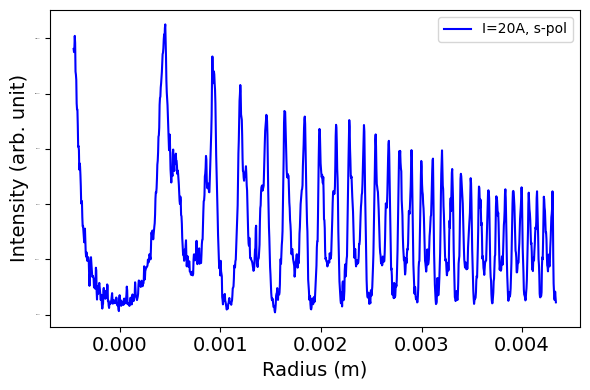

In [22]:
# *** plot line-outs from images vs radius ***
mpl.rcParams.update({'font.size': 10})              # changes font size for plots
mpl.figure(figsize=(6,4))
mpl.rc('xtick', labelsize=14)   
mpl.rc('ytick', labelsize=0)   
mpl.xlabel('Radius (m)', fontsize=14)
mpl.ylabel('Intensity (arb. unit)', fontsize=14)

mpl.plot(radius_0A_lin,data_image1[:,380:420].sum(axis=1),'b', markersize=3,label='I=20A, s-pol') 

#mpl.xlim(300,495)
mpl.legend()
mpl.tight_layout()


## Plotting data as a function of energy

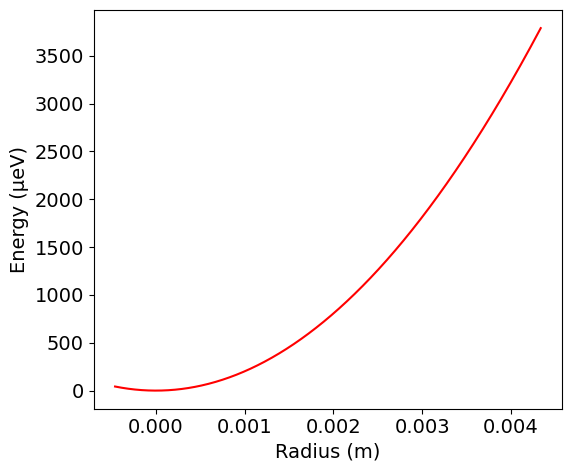

In [23]:
# *** Define energy axis ***
# **************************

energyaxis = radius_0A_lin**2*lambda2eV/(2*lambda0*focus**2)*1e6   # - Eoffset

# *** The energy offset Eoffset can be set in order to get the first fully resolved interference order centered at E=0 ***


mpl.rcParams.update({'font.size': 16})              # changes font size for plots
mpl.rc('xtick', labelsize=14)   
mpl.rc('ytick', labelsize=14)   
mpl.figure(figsize=(6,5))
mpl.ylabel('Energy (µeV)', fontsize=14)
mpl.xlabel('Radius (m)', fontsize=14)

mpl.plot(radius_0A_lin,energyaxis,'r', markersize=3,label='I=0A') 
mpl.tight_layout()



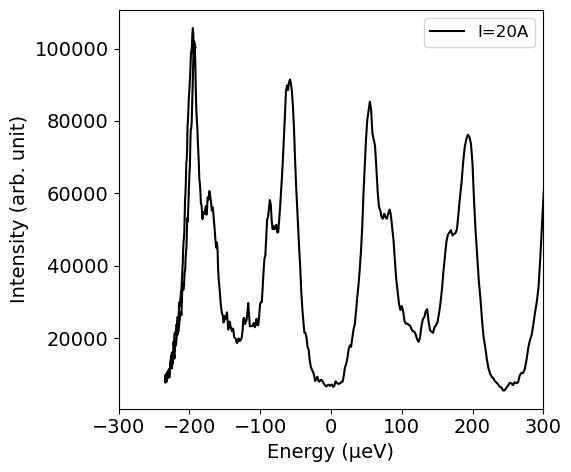

In [57]:
# *** plot line-outs from images vs energy ***
mpl.rcParams.update({'font.size': 16})              # changes font size for plots
mpl.rc('xtick', labelsize=14)   
mpl.rc('ytick', labelsize=14)   
mpl.figure(figsize=(6,5))
mpl.xlabel('Energy (µeV)', fontsize=14)
mpl.ylabel('Intensity (arb. unit)', fontsize=14)

mpl.plot(energyaxis-234,(data_image1[:,380:420]-data_d1[:,380:420]*6/50).sum(axis=1),'k', markersize=3,label='I=20A') 

mpl.xlim(-300,300)
#mpl.ylim(-.2,2.5e8)
mpl.legend(fontsize= 12)
mpl.tight_layout()


In [59]:
def lorentzian_res(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of a lorentzian function"""
    back = params['back']
    amp = params['amp']
    gamma = params['gamma']
    x0 = params['x0']

    model = back + amp * gamma**2/ ((x - x0)**2 + gamma**2) 

    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data

def FP_6_lorentzian(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of 6 lorentzian peaks"""
    back = params['back']

    amp1 = params['amp1']
    gamma1 = params['gamma1']
    xref1 = params['xref1']
    amp2 = params['amp2']
    gamma2 = params['gamma2']
    xref2 = params['xref2']
    amp3 = params['amp3']
    gamma3 = params['gamma3']
    xref3 = params['xref3']

    amp4 = params['amp4']
    gamma4 = params['gamma4']
    xref4 = params['xref4']
    amp5 = params['amp5']
    gamma5 = params['gamma5']
    xref5 = params['xref5']
    amp6 = params['amp6']
    gamma6 = params['gamma6']
    xref6 = params['xref6']
    
    model = back + amp1 * gamma1**2/ ((x - xref1)**2 + gamma1**2) 
    model +=       amp2 * gamma2**2/ ((x - xref2)**2 + gamma2**2) 
    model +=       amp3 * gamma3**2/ ((x - xref3)**2 + gamma3**2) 
    model +=       amp4 * gamma4**2/ ((x - xref4)**2 + gamma4**2) 
    model +=       amp5 * gamma5**2/ ((x - xref5)**2 + gamma5**2) 
    model +=       amp6 * gamma6**2/ ((x - xref6)**2 + gamma6**2) 


    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data


# *** fitting function with coupled parameters for Zeeman splitting of Hg 546nm line ***
def FP_6_lorentzian_coupled(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of 6 lorentzian peaks with fixed relative splitting and intensity ratios"""

    # definition of parameters
    origin =    params['origin']
    back =      params['back']
    splitting = params['splitting']
    gamma =     params['gamma']
    ratio12 =   params['ratio12']
    ratio13 =   params['ratio13']
    amp1p =     params['amp1p']
    amp1m =     params['amp1m']
   
    # definition of lorentzians with coupled parameters
    amp1 = amp1p
    gamma1 = gamma
    xref1 = origin + 2*splitting
    amp2 = amp1p / ratio12
    gamma2 = gamma
    xref2 = origin + 3*splitting
    amp3 = amp1p / ratio13
    gamma3 = gamma
    xref3 = origin + 4*splitting

    amp4 = amp1m
    gamma4 = gamma
    xref4 = origin - 2*splitting
    amp5 = amp1p / ratio12
    gamma5 = gamma
    xref5 = origin - 3*splitting
    amp6 = amp1p / ratio13
    gamma6 = gamma
    xref6 = origin - 4*splitting
   
    # *** fitting function ***
    model = back + amp1 * gamma1**2/ ((x - xref1)**2 + gamma1**2) 
    model +=       amp2 * gamma2**2/ ((x - xref2)**2 + gamma2**2) 
    model +=       amp3 * gamma3**2/ ((x - xref3)**2 + gamma3**2) 
    model +=       amp4 * gamma4**2/ ((x - xref4)**2 + gamma4**2) 
    model +=       amp5 * gamma5**2/ ((x - xref5)**2 + gamma5**2) 
    model +=       amp6 * gamma6**2/ ((x - xref6)**2 + gamma6**2) 


    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data


# *** fitting function with coupled parameters for Zeeman splitting of Hg 546nm line ***
# *** including 3 Lorentzians of the left and right subsequent orders of the Fabri Perot ***
def FP_12_lorentzian_coupled(params, x, data = None, eps_data = None):
    """lmfit: same as function before, but in addition considering 6 more peaks from higher and lower order"""

    # definition of parameters
    origin =    params['origin']
    back =      params['back']
    splitting = params['splitting']
    gamma =     params['gamma']
    ratio12 =   params['ratio12']
    ratio13 =   params['ratio13']
    amp1p =     params['amp1p']
    amp1m =     params['amp1m']
    odistance = params['odistance']
   
    # definition of lorentzians with coupled parameters
    amp1 = amp1p
    gamma1 = gamma
    xref1 = origin + 2*splitting
    amp2 = amp1p / ratio12
    gamma2 = gamma
    xref2 = origin + 3*splitting
    amp3 = amp1p / ratio13
    gamma3 = gamma
    xref3 = origin + 4*splitting

    amp4 = amp1m
    gamma4 = gamma
    xref4 = origin - 2*splitting
    amp5 = amp1p / ratio12
    gamma5 = gamma
    xref5 = origin - 3*splitting
    amp6 = amp1p / ratio13
    gamma6 = gamma
    xref6 = origin - 4*splitting
    
    
   
    # *** fitting function ***
    model = back + amp1 * gamma1**2/ ((x - xref1)**2 + gamma1**2) 
    model +=       amp2 * gamma2**2/ ((x - xref2)**2 + gamma2**2) 
    model +=       amp3 * gamma3**2/ ((x - xref3)**2 + gamma3**2) 
    model +=       amp4 * gamma4**2/ ((x - xref4)**2 + gamma4**2) 
    model +=       amp5 * gamma5**2/ ((x - xref5)**2 + gamma5**2) 
    model +=       amp6 * gamma6**2/ ((x - xref6)**2 + gamma6**2) 
    
    model +=       amp1 * gamma1**2/ ((x - xref1 + odistance)**2 + gamma1**2) 
    model +=       amp2 * gamma2**2/ ((x - xref2 + odistance)**2 + gamma2**2) 
    model +=       amp3 * gamma3**2/ ((x - xref3 + odistance)**2 + gamma3**2) 

    model +=       amp4 * gamma4**2/ ((x - xref4 - odistance)**2 + gamma4**2) 
    model +=       amp5 * gamma5**2/ ((x - xref5 - odistance)**2 + gamma5**2) 
    model +=       amp6 * gamma6**2/ ((x - xref6 - odistance)**2 + gamma6**2) 



    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data
 
    

    
    

### Initialize fit

In [60]:
# lmfit: initialize parameters for lorentzian fit
lorparams = Parameters()
lorparams.add('back', value=400, vary = True)
lorparams.add('amp', value = 178000, vary = True)    # [vary=False] would fix this parameter to the given value
lorparams.add('gamma', value = 0.00005, vary = True)
lorparams.add('x0', value = 0.00104, vary = True) 


In [61]:
# lmfit: initialize parameters for lorentzian fit transformed to Fabri-Perot rings
FPlorparams = Parameters()
FPlorparams.add('back', value=16000, vary = False)
FPlorparams.add('amp', value = 50000, vary = True)    # [vary=False] would fix this parameter to the given value
FPlorparams.add('gamma', value = 0.00001, vary = True)
FPlorparams.add('xref', value = 0.00104, vary = True) 
FPlorparams.add('focus', value = 0.0755, vary = False) 

In [62]:
# lmfit: initialize parameters for 6 lorentzian fit
lor6params = Parameters()
lor6params.add('back', value=16000, vary = True)
lor6params.add('amp1', value = 50000, vary = True)    # [vary=False] would fix this parameter to the given value
lor6params.add('gamma1', value = 0.00005, vary = True)
lor6params.add('x01', value = 0.00104, vary = True) 
lor6params.add('amp2', value = 50000, vary = True)    
lor6params.add('gamma2', value = 0.00005, vary = True)
lor6params.add('x02', value = 0.00104, vary = True) 
lor6params.add('amp3', value = 50000, vary = True)   
lor6params.add('gamma3', value = 0.00005, vary = True)
lor6params.add('x03', value = 0.00104, vary = True) 
lor6params.add('amp4', value = 50000, vary = True)   
lor6params.add('gamma4', value = 0.00005, vary = True)
lor6params.add('x04', value = 0.00104, vary = True) 
lor6params.add('amp5', value = 50000, vary = True)    
lor6params.add('gamma5', value = 0.00005, vary = True)
lor6params.add('x05', value = 0.00104, vary = True) 
lor6params.add('amp6', value = 50000, vary = True)    
lor6params.add('gamma6', value = 0.00005, vary = True)
lor6params.add('x06', value = 0.00104, vary = True) 



In [63]:
# lmfit: initialize parameters for 6 lorentzian fit
lor6coupledparams = Parameters()
lor6coupledparams.add('back', value=16000, vary = True)
lor6coupledparams.add('amp1p', value = 50000, vary = True)    # [vary=False] would fix this parameter to the given value
lor6coupledparams.add('amp1m', value = 50000, vary = True)    # [vary=False] would fix this parameter to the given value
lor6coupledparams.add('gamma', value = 0.00005, vary = True)
lor6coupledparams.add('origin', value = 0.00005, vary = True)
lor6coupledparams.add('splitting', value = 0.00005, vary = True)
lor6coupledparams.add('ratio12', value = 0.00005, vary = True)
lor6coupledparams.add('ratio13', value = 0.00005, vary = True)

### Perform fit

In [64]:
# *** Fit Lorentzian to lowest interference order of spectrum without B field to get resolution ***
# *************************************************************************************************

# lmfit: do fitting
minnerlor = Minimizer(lorentzian_res, lorparams, fcn_args=(energyaxis[300:480],((data_image6[:,380:420]-data_d2[:,380:420]/50).sum(axis=1))[300:480]))
resultlor = minnerlor.minimize()
finallor =  resultlor.residual
minnerFPlor = Minimizer(FP_lorentzian_res, FPlorparams, fcn_args=(energyaxis[300:480],((data_image6[:,380:420]-data_d2[:,380:420]/50).sum(axis=1))[300:480]))
resultFPlor = minnerFPlor.minimize()
finalFPlor =  resultFPlor.residual
# print results
report_fit(resultlor)
resultlor.params.pretty_print()


NameError: name 'data_image6' is not defined

### Plot results

<IPython.core.display.Javascript object>


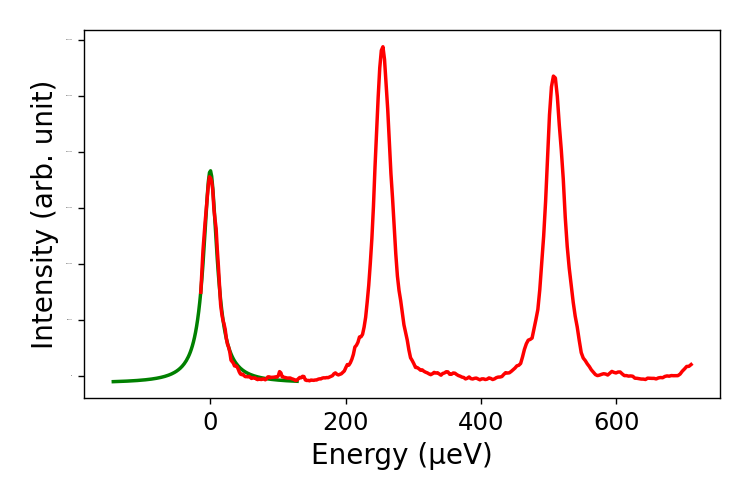

In [54]:
mpl.rcParams.update({'font.size': 16})              # changes font size for plots
mpl.rc('xtick', labelsize=14)   
mpl.rc('ytick', labelsize=0)   
mpl.figure(figsize=(6,4))
mpl.plot(energyaxis[300:480],((data_image6[:,380:420]-data_d2[:,380:420]/50).sum(axis=1))[300:480]-finallor,'g', linewidth=2,zorder=10)   
mpl.plot(energyaxis[400:700],((data_image6[:,380:420]-data_d2[:,380:420]/50).sum(axis=1))[400:700],'r', linewidth=2,zorder=10)   
#mpl.errorbar(xx, lordata, yerr=.05, fmt=".")
#mpl.plot((pixel[700:730]-944)*4.65,inten[700:730],'r', linewidth=2,zorder=10)   
#mpl.xlim(.00075,.00129)
#mpl.xlim(-300,300)
#mpl.ylim(15000,60000)
mpl.xlabel('Energy (µeV)')
mpl.ylabel('Intensity (arb. unit)')
mpl.tight_layout()

#mpl.savefig("Zeeman_lorfit.png") 